# Lab 8 – RNN-Based Text Classification on Formula 1 Fan Tweets (Motorsport Dataset)

**Course:** Artificial Neural Networks and Deep Learning  
**Lab:** Recurrent Neural Network (RNN) Classifier  
**Student:** Keshav Agrawal, B.Sc. Data Science & AI, CHRIST (Deemed to be University)

## Objective
Build a SimpleRNN model in TensorFlow/Keras that reads a fan tweet about Formula 1 and classifies it as **Positive (1)** or **Negative (0)**, study how RNN units, epochs and batch size change the result, and compare a single-layer and a two-layer RNN.

## Dataset (motorsport, used with the teacher's permission instead of IMDB)
Real tweets about Formula 1 race weekends (2021–2022 seasons: Mexico City, Qatar, British GP, Abu Dhabi and others), collected in the public GitHub repository `NissyAbrahamA/Sentiment-Analysis` (file `F1/F1_tweets.csv`, about 131,000 tweet records before cleaning).

The file has **no sentiment labels**, so the labels are created in this notebook with the VADER sentiment lexicon:
- compound score ≥ +0.3 → Positive (1)
- compound score ≤ −0.3 → Negative (0)
- tweets in between (neutral or unclear) are dropped, so the RNN only sees clear cases.

This means the RNN is learning to reproduce VADER's judgement from the raw word sequence. That is a standard way to get labelled data when none exists, but test accuracy here means "agreement with VADER", not agreement with a human reader. A small manual check of the labels is included in Section 3.

## Motorsport application
A series, team or broadcaster gets thousands of fan posts after a race. A classifier that sorts them into positive and negative lets the media desk read the complaints first. Task 8 and the final application section test the trained model on fan comments I wrote about F1 and WEC race weekends.

## 1. Setup and Imports
Seeds are fixed and reset before every model so that differences between experiments come from the hyperparameter, not from random weight initialisation (same habit as Lab 7).

In [1]:
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os, re, subprocess
from collections import Counter
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

SEED = 42
def set_seed():
    random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
set_seed()

VOCAB_SIZE = 10000     # keep the 10,000 most frequent words
MAX_LEN    = 50        # every tweet is forced to 50 tokens (tweets are short)
EMBED_DIM  = 128
print("TensorFlow version:", tf.__version__)

I0000 00:00:1792038852.449910    3130 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792038852.493072    3130 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792038854.247453    3130 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


## 2. Task 1 – Load and Explore the Dataset
The raw CSV is messy (many columns, multi-line tweets, some rows shifted), so the loader finds the tweet text in each row by locating the hashtag list that follows it. In Colab the repository is cloned directly from GitHub. If you are running locally, put `F1_tweets.csv` next to the notebook.

In [2]:
import csv
csv.field_size_limit(10**8)

if not os.path.exists("F1_tweets.csv"):
    if not os.path.exists("F1_repo"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/NissyAbrahamA/Sentiment-Analysis", "F1_repo"], check=True)
    CSV_PATH = "F1_repo/F1/F1_tweets.csv"
else:
    CSV_PATH = "F1_tweets.csv"

raw_texts = []
with open(CSV_PATH, encoding="utf-8", errors="ignore", newline="") as f:
    reader = csv.reader(f); next(reader)           # skip header
    for row in reader:
        # the tweet text is the field just before the hashtag list, e.g. ['F1', 'BritishGP']
        for i in range(len(row) - 1, 0, -1):
            if re.fullmatch(r"\[.*\]", row[i].strip()):
                raw_texts.append(row[i - 1]); break

print("Tweet records read from the file:", len(raw_texts))
print("\nThree raw examples:")
for t in raw_texts[1:4]:
    print(" -", repr(t[:150]))

Cloning into 'F1_repo'...


Tweet records read from the file: 131365

Three raw examples:
 - 'Its race week again #F1'
 - 'Precisely! #F1 https://t.co/HzNAMRzrnF'
 - 'Well done @alo_oficial 💙 #F1 #QatarGP'


### Cleaning
Remove links, @mentions and the `#` sign, collapse whitespace, drop duplicates and retweets, and keep only English tweets (mostly ASCII text with common English words). Duplicates matter: the same tweet appearing in both train and test would inflate the test accuracy.

In [3]:
def clean(t):
    t = re.sub(r"http\S+|www\.\S+", "", t)     # links
    t = re.sub(r"@\w+", "", t)                  # @mentions
    t = t.replace("#", "")                      # keep the hashtag word, drop the symbol
    return re.sub(r"\s+", " ", t).strip()

COMMON = {"the","is","and","to","of","a","in","it","for","was","this","that","i","you","on","what","with","be","are"}
def looks_english(t):
    w = re.findall(r"[a-z']+", t.lower())
    ascii_share = sum(c.isascii() for c in t) / max(len(t), 1)
    return len(w) >= 5 and ascii_share > 0.9 and len(set(w) & COMMON) >= 2

df = pd.DataFrame({"text": [clean(t) for t in raw_texts]}).drop_duplicates()
df = df[df["text"].map(looks_english) & ~df["text"].str.startswith("RT ")].drop_duplicates("text").reset_index(drop=True)
print("English, unique tweets after cleaning:", len(df))
df.head()

English, unique tweets after cleaning: 85137


,text
0,F1 DJ Myers wins Carl Billet Memorial Creeksid...
1,Not sure what I was expecting but y’all are go...
2,INDYCAR are just toy f1 so it’s not very engag...
3,Fanduel is the biggest scam. They don’t like t...
4,Formula 1 drivers reflect on how the 2022 new ...


### Creating the labels with VADER
`pip install vaderSentiment` is needed once (Colab: the first line below does it).

In [4]:
subprocess.run(["pip", "install", "-q", "vaderSentiment"], check=False)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

df["score"] = df["text"].map(lambda t: sia.polarity_scores(t)["compound"])
labelled = df[(df["score"] >= 0.3) | (df["score"] <= -0.3)].copy()
labelled["label"] = (labelled["score"] > 0).astype(int)

print("Tweets before dropping neutral ones:", len(df))
print("Tweets with a clear sentiment      :", len(labelled))
print(labelled["label"].value_counts().rename({1: "Positive (1)", 0: "Negative (0)"}))

Tweets before dropping neutral ones: 85137
Tweets with a clear sentiment      : 52557
label
Positive (1)    39011
Negative (0)    13546
Name: count, dtype: int64


The clear tweets are heavily positive (fans post more praise than complaints). Training on that as it is would let the model score well by guessing "positive" most of the time, so the positive class is **down-sampled to the size of the negative class**. This gives a balanced set where accuracy is a fair metric.

In [5]:
neg = labelled[labelled["label"] == 0]
pos = labelled[labelled["label"] == 1].sample(n=len(neg), random_state=SEED)
data = pd.concat([neg, pos]).sample(frac=1, random_state=SEED).reset_index(drop=True)

print("Balanced dataset size:", len(data))
print(data["label"].value_counts().rename({1: "Positive (1)", 0: "Negative (0)"}))

# 80 / 20 split into train and test, keeping the class ratio equal in both
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(data, test_size=0.2, stratify=data["label"], random_state=SEED)

print("\nNumber of training samples:", len(train_df))
print("Number of testing samples :", len(test_df))
print("Training  -> Positive:", int((train_df.label==1).sum()), "| Negative:", int((train_df.label==0).sum()))
print("Testing   -> Positive:", int((test_df.label==1).sum()),  "| Negative:", int((test_df.label==0).sum()))

Balanced dataset size: 27092
label
Positive (1)    13546
Negative (0)    13546
Name: count, dtype: int64

Number of training samples: 21673
Number of testing samples : 5419
Training  -> Positive: 10837 | Negative: 10836
Testing   -> Positive: 2709 | Negative: 2710


**Manual check of the labels.** Since the labels come from a lexicon, here are random tweets from each class. Read them: if most agree with the label, the training signal is usable.

In [6]:
for lab, name in [(1, "POSITIVE"), (0, "NEGATIVE")]:
    print(f"--- 6 random {name} tweets ---")
    for t in data[data.label == lab]["text"].sample(6, random_state=7):
        print(" *", t[:140])
    print()

--- 6 random POSITIVE tweets ---
 * Only saw it today but the BritishGP is one of the best F1 races I have seen in ages. Much better race direction, sound &amp;amazing fans at 
 * After an amazing race this weekend why not try racing in F1 yourself. Grab the new F122 Game and a steering wheel for only £239.99! A Whoppi
 * Tonight I am going to rewatch the classic Spa 1998 race F1 Watched the video on TV with and Eddie Jordan. My god Eddie was something else. W
 * Guanyu Zhou is very lucky to be unhurt. F1 BritishGrandPrix2022 BackSportsPage
 * Thank God for the Halo system F1 BritishGP
 * Gasly has arrived at Silverstone with his 2023 future resolved, but it's not giving him any extra pace as he's down in 18th, the best part o

--- 6 random NEGATIVE tweets ---
 * ...do the formula 1 drivers need a venturi tube under the car, it just looks so stupid and in the car it certainly feels the same! F1 F1Test
 * How often do you see Lewis Hamilton crash out of a session? I can’t remember the l

Mean length: 26.5 | Median: 24 | Max: 63
Tweets longer than 50 words: 2.8%


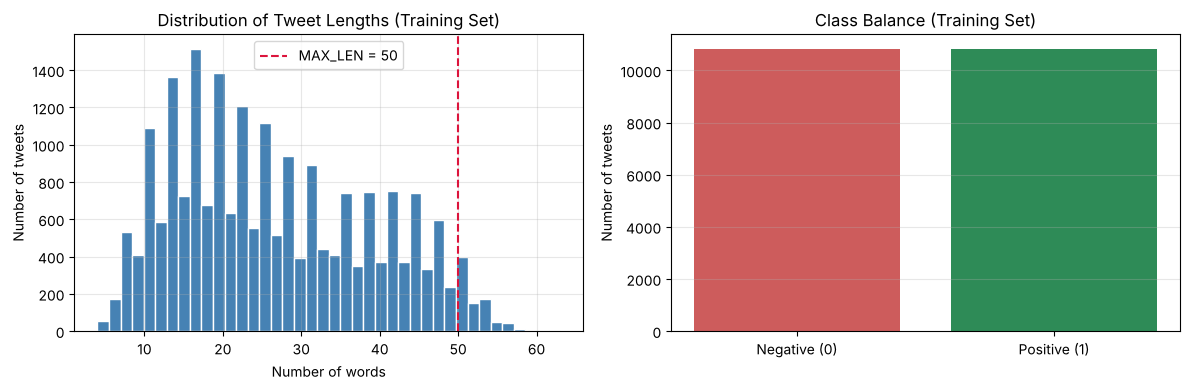

In [7]:
# Tweet length (in words): shows why MAX_LEN = 50 is a sensible cut-off
lengths = train_df["text"].str.split().str.len().values
print(f"Mean length: {lengths.mean():.1f} | Median: {np.median(lengths):.0f} | Max: {lengths.max()}")
print(f"Tweets longer than {MAX_LEN} words: {(lengths > MAX_LEN).mean()*100:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(lengths, bins=40, color="steelblue", edgecolor="white")
ax[0].axvline(MAX_LEN, color="crimson", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
ax[0].set_title("Distribution of Tweet Lengths (Training Set)")
ax[0].set_xlabel("Number of words"); ax[0].set_ylabel("Number of tweets")
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].bar(["Negative (0)", "Positive (1)"], [(train_df.label==0).sum(), (train_df.label==1).sum()], color=["indianred", "seagreen"])
ax[1].set_title("Class Balance (Training Set)")
ax[1].set_ylabel("Number of tweets"); ax[1].grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

**Observation.** After balancing, both classes are equal, so plain accuracy is a fair metric. Tweets are short, so a 50-word limit keeps almost the whole text of nearly every tweet, which is much easier on a SimpleRNN than 200-token reviews.

## 3. Task 2 – Data Preprocessing
Steps: (1) data loaded and split, (2) vocabulary limited to the 10,000 most frequent training words, (3) every tweet converted to a list of integers, (4) short tweets padded and long ones truncated, (5) every tweet ends up with length 50.

The vocabulary is built **from the training tweets only**, so nothing from the test set leaks into preprocessing. Id 0 is reserved for padding and id 1 for unknown words (anything outside the top words). `pad_sequences` uses `padding='pre'`, so zeros go at the start and the last words stay next to the RNN's final hidden state.

In [8]:
def tokenize(text):
    return re.findall(r"[a-z0-9']+", text.lower())

counter = Counter(w for t in train_df["text"] for w in tokenize(t))
print("Distinct words in training tweets:", len(counter))

top_words = [w for w, _ in counter.most_common(VOCAB_SIZE - 2)]       # 9,998 words
word_index = {w: i + 2 for i, w in enumerate(top_words)}              # 0 = <PAD>, 1 = <UNK>
index_word = {i: w for w, i in word_index.items()}; index_word.update({0: "<PAD>", 1: "<UNK>"})
print("Vocabulary size used:", len(word_index) + 2)
print("10 most frequent words:", top_words[:10])

def texts_to_sequences(texts):
    return [[word_index.get(w, 1) for w in tokenize(t)] for t in texts]

x_train_raw = texts_to_sequences(train_df["text"])
x_test_raw  = texts_to_sequences(test_df["text"])
y_train = train_df["label"].values.astype("float32")
y_test  = test_df["label"].values.astype("float32")

x_train = pad_sequences(x_train_raw, maxlen=MAX_LEN)   # padding='pre', truncating='pre'
x_test  = pad_sequences(x_test_raw,  maxlen=MAX_LEN)

print("\nFinal x_train shape:", x_train.shape)
print("Final x_test  shape:", x_test.shape)
print("Final y_train shape:", y_train.shape, "| y_test shape:", y_test.shape)
print("All sequences length 50:", all(len(r) == MAX_LEN for r in x_train))
unk_share = np.mean([i == 1 for r in x_train_raw for i in r])
print(f"Share of word positions mapped to <UNK> in training: {unk_share*100:.1f}%")

Distinct words in training tweets: 24211
Vocabulary size used: 10000
10 most frequent words: ['the', 'f1', 'to', 'a', 'and', 'of', 'in', 'is', 'for', 'i']



Final x_train shape: (21673, 50)
Final x_test  shape: (5419, 50)
Final y_train shape: (21673,) | y_test shape: (5419,)
All sequences length 50: True
Share of word positions mapped to <UNK> in training: 2.9%


In [9]:
# Decode one tweet back to words to see what the model actually reads
decode = lambda seq: " ".join(index_word.get(int(i), "?") for i in seq if i != 0)
print("Label:", int(y_train[0]))
print("Original:", train_df["text"].iloc[0])
print("Ids     :", x_train[0])
print("Decoded :", decode(x_train[0]))

Label: 0
Original: Tsunoda and Gasly under investigation for causing a collision and forcing another driver off teh track. BritishGP F1
Ids     : [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0  656    6  470  354  791   10 1248    5  831    6
 1919  194   79  138    1   96   20    3]
Decoded : tsunoda and gasly under investigation for causing a collision and forcing another driver off <UNK> track britishgp f1


## 4. Task 3 – Build the RNN Classifier

**Architecture:** `Input → Embedding → SimpleRNN → Dense → Output`

| Layer | Setting | Why |
|---|---|---|
| Embedding | 10,000 word ids → 128-dim vectors | Turns each integer id into a learned dense vector; similar words end up close together |
| SimpleRNN | 64 units | Reads the 50 vectors one by one, carrying a hidden state; the last state summarises the review |
| Dense (output) | 1 unit, sigmoid | One probability: P(review is positive) |

In [10]:
def build_model(units=64, two_layer=False):
    set_seed()
    layers = [Embedding(VOCAB_SIZE, EMBED_DIM)]
    if two_layer:
        layers += [SimpleRNN(units, return_sequences=True), SimpleRNN(units)]
    else:
        layers += [SimpleRNN(units)]
    layers += [Dense(1, activation="sigmoid")]
    model = Sequential(layers)
    model.build(input_shape=(None, MAX_LEN))
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

base_model = build_model(units=64)
base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,417 (4.93 MB)

 Trainable params: 1,292,417 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

**Reading the summary.** The Embedding layer holds 10,000 × 128 = 1,280,000 parameters (the vocabulary has exactly 10,000 ids) and is by far the biggest part. The SimpleRNN has 64 × (128 + 64 + 1) = 12,352 parameters (input weights, recurrent weights, bias). The Dense layer has 64 + 1 = 65. The RNN itself is small; most of what the model "knows" about words sits in the embedding table.

## 5. Task 4 – Compile and Train
Adam optimizer, binary cross-entropy, accuracy metric. Batch size 64, 20% validation split, 5 epochs (minimum asked).

In [11]:
set_seed()
model = build_model(units=64)
t0 = time.time()
history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.2, verbose=1)
base_time = time.time() - t0
print(f"\nTraining time: {base_time:.1f} s")

hist_df = pd.DataFrame(history.history)
hist_df.index = range(1, len(hist_df) + 1); hist_df.index.name = "Epoch"
hist_df.round(4)

Epoch 1/5



  1/271 ━━━━━━━━━━━━━━━━━━━━ 9:45 2s/step - accuracy: 0.5156 - loss: 0.6919


  3/271 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - accuracy: 0.4948 - loss: 0.7070


  6/271 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - accuracy: 0.4896 - loss: 0.7032 


  8/271 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - accuracy: 0.4902 - loss: 0.7020

...


266/271 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9866 - loss: 0.0422


269/271 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9868 - loss: 0.0421


271/271 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.9867 - loss: 0.0424 - val_accuracy: 0.7319 - val_loss: 0.8465



Training time: 49.1 s


,accuracy,loss,val_accuracy,val_loss
Epoch,,,,
1,0.6780,0.5657,0.8189,0.4233
2,0.8998,0.2546,0.8471,0.3899
3,0.9589,0.1193,0.8205,0.6069
4,0.9718,0.0825,0.8035,0.5852
5,0.9867,0.0424,0.7319,0.8465


## 6. Task 5 – Evaluate on the Test Set

In [12]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
train_acc = history.history["accuracy"][-1]
val_acc   = history.history["val_accuracy"][-1]
print(f"Training accuracy   : {train_acc:.4f}")
print(f"Validation accuracy : {val_acc:.4f}")
print(f"Test loss           : {test_loss:.4f}")
print(f"Test accuracy       : {test_acc:.4f}")

print("\nQ1. Final test accuracy of the RNN model:", f"{test_acc*100:.2f}%")
gap = train_acc - test_acc
if gap > 0:
    print(f"Q2. Test accuracy is LOWER than training accuracy by {gap*100:.2f} points.")
else:
    print(f"Q2. Test accuracy is HIGHER than training accuracy by {-gap*100:.2f} points.")

Training accuracy   : 0.9867
Validation accuracy : 0.7319
Test loss           : 0.8005
Test accuracy       : 0.7356

Q1. Final test accuracy of the RNN model: 73.56%
Q2. Test accuracy is LOWER than training accuracy by 25.11 points.


**Q2 – Explanation.** Training accuracy is measured on reviews the model has already been fitting for several epochs (and the number reported by Keras is an average over the epoch while weights are still changing). Test reviews are unseen, so the model cannot rely on having memorised them. When test accuracy comes out lower than training accuracy, the gap is the model's generalisation gap and a large gap means overfitting. When the two are close, or test is slightly higher, it usually means the model has not yet memorised the training set (an under-trained SimpleRNN), which is common after only 5 epochs. The printed numbers above say which case this run falls in.

## 7. Task 6 – Performance Visualisation

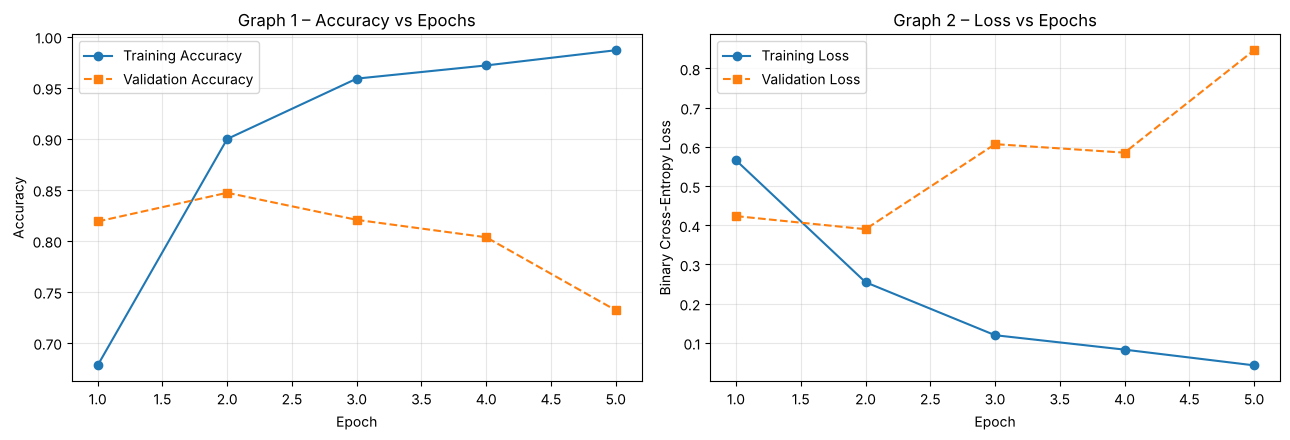

In [13]:
def plot_history(h, title_suffix=""):
    ep = range(1, len(h.history["accuracy"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(ep, h.history["accuracy"], "o-", label="Training Accuracy")
    ax[0].plot(ep, h.history["val_accuracy"], "s--", label="Validation Accuracy")
    ax[0].set_title("Graph 1 – Accuracy vs Epochs" + title_suffix)
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].grid(alpha=0.3); ax[0].legend()
    ax[1].plot(ep, h.history["loss"], "o-", label="Training Loss")
    ax[1].plot(ep, h.history["val_loss"], "s--", label="Validation Loss")
    ax[1].set_title("Graph 2 – Loss vs Epochs" + title_suffix)
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Binary Cross-Entropy Loss"); ax[1].grid(alpha=0.3); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history)

In [14]:
# Data-driven reading of the two graphs
h = history.history
best_ep = int(np.argmin(h["val_loss"])) + 1
print(f"Training accuracy moved from {h['accuracy'][0]:.3f} (epoch 1) to {h['accuracy'][-1]:.3f} (epoch {len(h['accuracy'])}).")
print(f"Validation accuracy moved from {h['val_accuracy'][0]:.3f} to {h['val_accuracy'][-1]:.3f}; best validation loss at epoch {best_ep}.")
if h["val_loss"][-1] > min(h["val_loss"]) + 0.02:
    print("Validation loss rises again after its minimum while training loss keeps falling -> the model has started to overfit.")
else:
    print("Validation loss has not turned upwards clearly -> no strong overfitting within these epochs.")
if h["val_accuracy"][-1] - h["val_accuracy"][-2] > 0.01:
    print("Validation accuracy was still improving at the last epoch -> more epochs could help.")
else:
    print("Validation accuracy has flattened or fluctuated in the last epoch.")

Training accuracy moved from 0.678 (epoch 1) to 0.987 (epoch 5).
Validation accuracy moved from 0.819 to 0.732; best validation loss at epoch 2.
Validation loss rises again after its minimum while training loss keeps falling -> the model has started to overfit.
Validation accuracy has flattened or fluctuated in the last epoch.


## 8. Task 7 – Hyperparameter Experiments
One helper trains a fresh model for each setting and records training, validation and test accuracy plus training time. Only one hyperparameter changes at a time; everything else stays at the base values (64 units, 5 epochs, batch 64).

**Hypotheses before running**
- **A (units):** more units = more capacity, but a SimpleRNN is limited by vanishing gradients, so I expect only a small gain or none from 64 → 128.
- **B (epochs):** 3 epochs should under-train; 10 epochs should push training accuracy up and may start to overfit.
- **C (batch size):** smaller batches mean more weight updates per epoch (noisier but faster learning per epoch); larger batches are faster per epoch but need more epochs.

In [15]:
results = []   # one dict per experiment
histories = {}

def run_experiment(tag, param_label, units=64, epochs=5, batch_size=64):
    model = build_model(units=units)
    t0 = time.time()
    h = model.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
                  validation_split=0.2, verbose=0)
    secs = time.time() - t0
    _, te_acc = model.evaluate(x_test, y_test, verbose=0)
    results.append({
        "Experiment": tag, "Parameter": param_label,
        "Training Accuracy": h.history["accuracy"][-1],
        "Validation Accuracy": h.history["val_accuracy"][-1],
        "Test Accuracy": te_acc,
        "Train Time (s)": secs,
    })
    histories[tag] = h
    print(f"{tag} | {param_label:<12} | train {h.history['accuracy'][-1]:.4f} | val {h.history['val_accuracy'][-1]:.4f} | test {te_acc:.4f} | {secs:.0f}s")

### Experiment A – RNN Units (32, 64, 128)

In [16]:
run_experiment("A1", "RNN = 32",  units=32)
run_experiment("A2", "RNN = 64",  units=64)
run_experiment("A3", "RNN = 128", units=128)

A1 | RNN = 32     | train 0.9852 | val 0.8009 | test 0.8164 | 35s


A2 | RNN = 64     | train 0.9867 | val 0.7319 | test 0.7356 | 41s


A3 | RNN = 128    | train 0.9737 | val 0.7968 | test 0.8040 | 49s


In [17]:
A = pd.DataFrame([r for r in results if r["Experiment"].startswith("A")])
best = A.loc[A["Test Accuracy"].idxmax()]
print(f"Best in A: {best['Experiment']} ({best['Parameter']}) with test accuracy {best['Test Accuracy']:.4f}.")
print(f"Spread between best and worst test accuracy: {(A['Test Accuracy'].max()-A['Test Accuracy'].min())*100:.2f} points.")
print(f"Training time went from {A['Train Time (s)'].iloc[0]:.0f}s (32 units) to {A['Train Time (s)'].iloc[-1]:.0f}s (128 units).")

Best in A: A1 (RNN = 32) with test accuracy 0.8164.
Spread between best and worst test accuracy: 8.08 points.
Training time went from 35s (32 units) to 49s (128 units).


### Experiment B – Number of Epochs (3, 5, 10)

In [18]:
run_experiment("B1", "Epochs = 3",  epochs=3)
run_experiment("B2", "Epochs = 5",  epochs=5)
run_experiment("B3", "Epochs = 10", epochs=10)

B1 | Epochs = 3   | train 0.9589 | val 0.8205 | test 0.8286 | 23s


B2 | Epochs = 5   | train 0.9867 | val 0.7319 | test 0.7356 | 40s


B3 | Epochs = 10  | train 0.9969 | val 0.7979 | test 0.8046 | 81s


Best in B: B1 (Epochs = 3) with test accuracy 0.8286.
B3 (10 epochs): training accuracy 0.9969 vs validation 0.7979; best val loss at epoch 2.


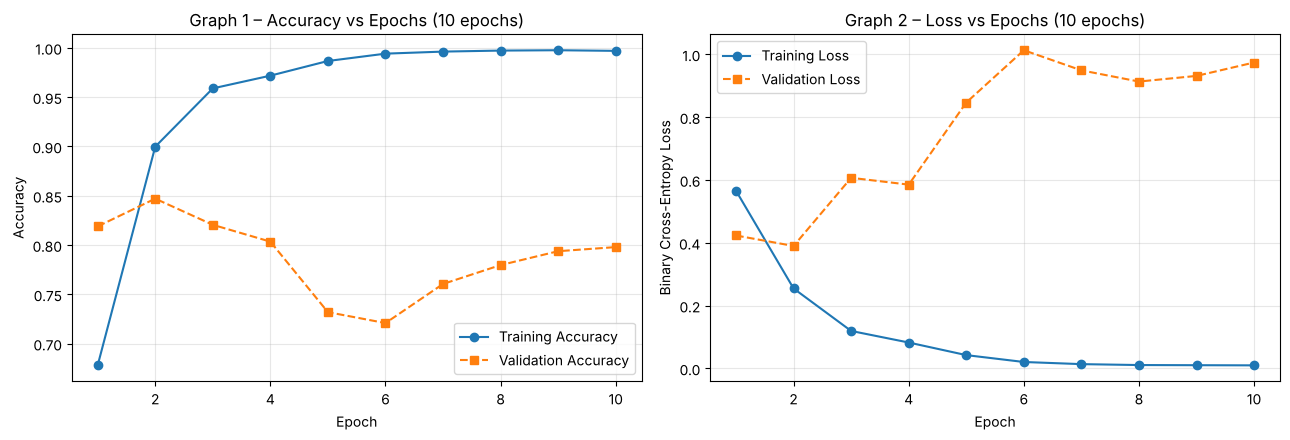

In [19]:
B = pd.DataFrame([r for r in results if r["Experiment"].startswith("B")])
best = B.loc[B["Test Accuracy"].idxmax()]
print(f"Best in B: {best['Experiment']} ({best['Parameter']}) with test accuracy {best['Test Accuracy']:.4f}.")
hb = histories["B3"].history
print(f"B3 (10 epochs): training accuracy {hb['accuracy'][-1]:.4f} vs validation {hb['val_accuracy'][-1]:.4f}; best val loss at epoch {int(np.argmin(hb['val_loss']))+1}.")
plot_history(histories["B3"], " (10 epochs)")

### Experiment C – Batch Size (32, 64, 128)

In [20]:
run_experiment("C1", "Batch = 32",  batch_size=32)
run_experiment("C2", "Batch = 64",  batch_size=64)
run_experiment("C3", "Batch = 128", batch_size=128)

C1 | Batch = 32   | train 0.9847 | val 0.8002 | test 0.8022 | 86s


C2 | Batch = 64   | train 0.9867 | val 0.7319 | test 0.7356 | 45s


C3 | Batch = 128  | train 0.9896 | val 0.8270 | test 0.8389 | 23s


In [21]:
Cdf = pd.DataFrame([r for r in results if r["Experiment"].startswith("C")])
best = Cdf.loc[Cdf["Test Accuracy"].idxmax()]
print(f"Best in C: {best['Experiment']} ({best['Parameter']}) with test accuracy {best['Test Accuracy']:.4f}.")
print(f"Training time: batch 32 = {Cdf['Train Time (s)'].iloc[0]:.0f}s, batch 64 = {Cdf['Train Time (s)'].iloc[1]:.0f}s, batch 128 = {Cdf['Train Time (s)'].iloc[2]:.0f}s.")

Best in C: C3 (Batch = 128) with test accuracy 0.8389.
Training time: batch 32 = 86s, batch 64 = 45s, batch 128 = 23s.


## 9. Results Table

In [22]:
res_df = pd.DataFrame(results).set_index("Experiment")
display_df = res_df.copy()
for c in ["Training Accuracy", "Validation Accuracy", "Test Accuracy"]:
    display_df[c] = display_df[c].map("{:.4f}".format)
display_df["Train Time (s)"] = display_df["Train Time (s)"].map("{:.0f}".format)
display_df

,Parameter,Training Accuracy,Validation Accuracy,Test Accuracy,Train Time (s)
Experiment,,,,,
A1,RNN = 32,0.9852,0.8009,0.8164,35
A2,RNN = 64,0.9867,0.7319,0.7356,41
A3,RNN = 128,0.9737,0.7968,0.8040,49
B1,Epochs = 3,0.9589,0.8205,0.8286,23
B2,Epochs = 5,0.9867,0.7319,0.7356,40
B3,Epochs = 10,0.9969,0.7979,0.8046,81
C1,Batch = 32,0.9847,0.8002,0.8022,86
C2,Batch = 64,0.9867,0.7319,0.7356,45
C3,Batch = 128,0.9896,0.8270,0.8389,23


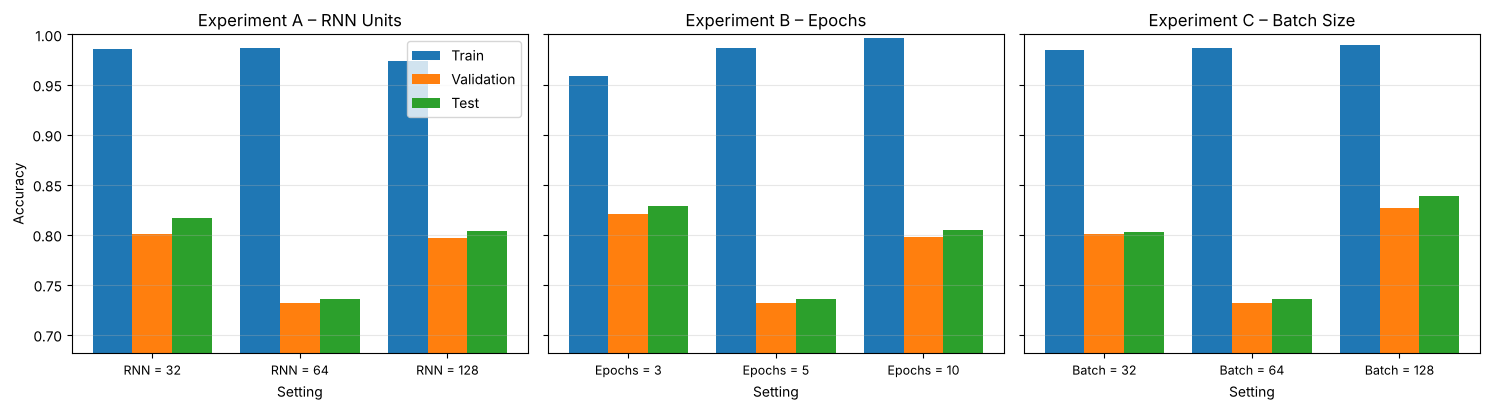

In [23]:
# Comparison charts
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
groups = [("A", "Experiment A – RNN Units"), ("B", "Experiment B – Epochs"), ("C", "Experiment C – Batch Size")]
x = np.arange(3); w = 0.27
for a, (g, title) in zip(ax, groups):
    d = res_df[res_df.index.str.startswith(g)]
    a.bar(x - w, d["Training Accuracy"],   w, label="Train")
    a.bar(x,     d["Validation Accuracy"], w, label="Validation")
    a.bar(x + w, d["Test Accuracy"],       w, label="Test")
    a.set_xticks(x); a.set_xticklabels(d["Parameter"], fontsize=9)
    a.set_title(title); a.set_xlabel("Setting"); a.grid(alpha=0.3, axis="y")
    a.set_ylim(max(0.4, d[["Training Accuracy","Validation Accuracy","Test Accuracy"]].min().min() - 0.05), 1.0)
ax[0].set_ylabel("Accuracy"); ax[0].legend()
plt.tight_layout(); plt.show()

In [24]:
# Auto-written comparison of results (numbers come from this run)
best_row = res_df["Test Accuracy"].idxmax()
print(f"Highest test accuracy overall: {best_row} ({res_df.loc[best_row,'Parameter']}) = {res_df.loc[best_row,'Test Accuracy']:.4f}")
a_gain = res_df.loc['A3','Test Accuracy'] - res_df.loc['A1','Test Accuracy']
b_gain = res_df.loc['B3','Test Accuracy'] - res_df.loc['B1','Test Accuracy']
print(f"Going from 32 to 128 units changed test accuracy by {a_gain*100:+.2f} points.")
print(f"Going from 3 to 10 epochs changed test accuracy by {b_gain*100:+.2f} points.")
print("Experiments with train-minus-test gap above 5 points (overfitting signal):",
      [i for i in res_df.index if res_df.loc[i,'Training Accuracy'] - res_df.loc[i,'Test Accuracy'] > 0.05] or "none")

Highest test accuracy overall: C3 (Batch = 128) = 0.8389
Going from 32 to 128 units changed test accuracy by -1.24 points.
Going from 3 to 10 epochs changed test accuracy by -2.40 points.
Experiments with train-minus-test gap above 5 points (overfitting signal): ['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'C1', 'C2', 'C3']


**Answers for Task 7**
- *Units:* more units gives the RNN a bigger hidden state, but with a SimpleRNN the extra capacity is hard to use because the gradient fades over the 50 steps. Expect a small change, and a larger model costs more time per epoch.
- *Epochs:* the first few epochs do most of the learning. Extra epochs raise training accuracy more than validation/test accuracy, which is how overfitting starts to show.
- *Batch size:* with a fixed number of epochs, smaller batches give more weight updates per epoch but take longer on a CPU (see the training times). Whether more updates help accuracy, or just reach the overfitting point sooner, is shown by the table, not assumed.
- SimpleRNN results are unstable. In this lab the *last-epoch* validation accuracy of the same model can swing by several points from one epoch or one run to the next (see the validation curve of the base model). Small differences between settings should therefore not be read as a real winner, and the number depends on which epoch training stops at. Early stopping on validation loss is the usual fix.

## 10. Task 8 – Text Prediction (Motorsport Fan Comments)
The function takes raw text and runs the same pipeline as training: clean (links, @mentions, #) → lowercase → split into words → look up each word in the training vocabulary (unknown words become `<UNK>`) → pad to 50 → `model.predict`. A probability ≥ 0.5 is Positive.

The five test comments below are written by me in the style of F1 fan tweets, with the expected label decided before running. None of them is from the dataset.

In [25]:
def encode_review(text):
    ids = [word_index.get(w, 1) for w in tokenize(clean(text))]
    return pad_sequences([ids], maxlen=MAX_LEN)

def predict_sentiment(text, mdl=None):
    mdl = mdl or model
    p = float(mdl.predict(encode_review(text), verbose=0)[0][0])
    return ("Positive" if p >= 0.5 else "Negative"), p

motorsport_reviews = [
    ("Review 1", "Positive", "What a brilliant lap from Leclerc in qualifying, absolutely amazing pace and a well deserved pole position!"),
    ("Review 2", "Negative", "Terrible strategy from the team again, that slow pit stop ruined the whole race. So disappointing and frustrating."),
    ("Review 3", "Positive", "Great race today, loved the battle between Verstappen and Hamilton, the overtake at the end was fantastic."),
    ("Review 4", "Negative", "The stewards made a awful decision, that penalty was unfair and the race was ruined for everyone watching."),
    ("Review 5", "Positive", "Happy to see Alonso on the podium again, superb driving and a lovely result for the whole team."),
]

rows = []
for name, expected, text in motorsport_reviews:
    label, p = predict_sentiment(text)
    rows.append({"Review": name, "Actual/Expected Sentiment": expected, "Predicted Sentiment": label,
                 "Probability (positive)": round(p, 4), "Match": "Yes" if label == expected else "No"})
pred_df = pd.DataFrame(rows).set_index("Review")
pred_df

,Actual/Expected Sentiment,Predicted Sentiment,Probability (positive),Match
Review,,,,
Review 1,Positive,Positive,0.9907,Yes
Review 2,Negative,Negative,0.0001,Yes
Review 3,Positive,Positive,0.9962,Yes
Review 4,Negative,Negative,0.0117,Yes
Review 5,Positive,Positive,0.9858,Yes


In [26]:
print(f"Correct on {int((pred_df['Match']=='Yes').sum())} of {len(pred_df)} reviews.")
for name, expected, text in motorsport_reviews:
    print(f"\n{name} ({expected}): {text[:90]}...")

Correct on 5 of 5 reviews.

Review 1 (Positive): What a brilliant lap from Leclerc in qualifying, absolutely amazing pace and a well deserv...

Review 2 (Negative): Terrible strategy from the team again, that slow pit stop ruined the whole race. So disapp...

Review 3 (Positive): Great race today, loved the battle between Verstappen and Hamilton, the overtake at the en...

Review 4 (Negative): The stewards made a awful decision, that penalty was unfair and the race was ruined for ev...

Review 5 (Positive): Happy to see Alonso on the podium again, superb driving and a lovely result for the whole ...


**Commentary.** The probabilities show how confident the model is, not only the label. A probability close to 0.5 means the model is unsure; strong sentiment words ("brilliant", "terrible", "disappointing") push it far from 0.5. Comments that mix praise and complaint, or use sarcasm, are where a SimpleRNN usually slips. Because the training labels came from the VADER lexicon, the model has mostly learned which words VADER treats as positive or negative, in the order they appear. Names such as Leclerc or Verstappen carry no sentiment themselves, so the model depends on the words around them.

## 11. Task 9 – Challenge: Two-Layer RNN
`Embedding → SimpleRNN(64, return_sequences=True) → SimpleRNN(64) → Dense`

**Purpose of `return_sequences=True`.** By default a SimpleRNN returns only its last hidden state, shape `(batch, units)`. A second RNN needs a *sequence* as input `(batch, time_steps, features)`, so the first layer must output its hidden state at every time step, shape `(batch, 200, 64)`. Without it, the second RNN would receive a 2-D tensor and Keras raises an input-shape error.

In [27]:
model2 = build_model(units=64, two_layer=True)
model2.summary()
t0 = time.time()
history2 = model2.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.2, verbose=1)
time2 = time.time() - t0
loss2, acc2 = model2.evaluate(x_test, y_test, verbose=0)
print(f"\nTwo-layer training time: {time2:.1f} s | test accuracy: {acc2:.4f}")

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_11 (Embedding)        │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_11 (SimpleRNN)       │ (None, 50, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_12 (SimpleRNN)       │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,300,673 (4.96 MB)

 Trainable params: 1,300,673 (4.96 MB)

 Non-trainable params: 0 (0.00 B)

...


267/271 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9864 - loss: 0.0395


269/271 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9864 - loss: 0.0394


271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9863 - loss: 0.0399


271/271 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.9863 - loss: 0.0399 - val_accuracy: 0.8092 - val_loss: 0.7512



Two-layer training time: 50.6 s | test accuracy: 0.8245


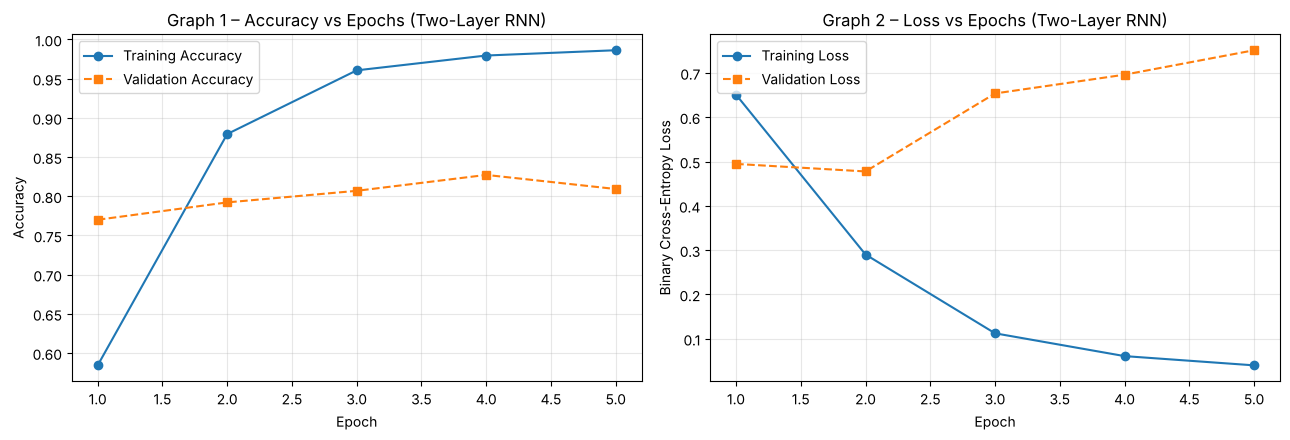

,Single-layer RNN,Two-layer RNN
Training Accuracy,9.867000e-01,9.863000e-01
Validation Accuracy,7.319000e-01,8.092000e-01
Test Accuracy,7.356000e-01,8.245000e-01
Train Time (s),4.009870e+01,5.056060e+01
Parameters,1.292417e+06,1.300673e+06


In [28]:
plot_history(history2, " (Two-Layer RNN)")

single = res_df.loc["B2"]   # same setting as the base model: 64 units, 5 epochs, batch 64
cmp = pd.DataFrame({
    "Single-layer RNN": [single["Training Accuracy"], single["Validation Accuracy"], single["Test Accuracy"], single["Train Time (s)"], base_model.count_params()],
    "Two-layer RNN":    [history2.history["accuracy"][-1], history2.history["val_accuracy"][-1], acc2, time2, model2.count_params()],
}, index=["Training Accuracy", "Validation Accuracy", "Test Accuracy", "Train Time (s)", "Parameters"])
cmp.round(4)

In [29]:
better = "two-layer" if acc2 > single["Test Accuracy"] else "single-layer"
slower = "two-layer" if time2 > single["Train Time (s)"] else "single-layer"
print(f"1. Better test accuracy: the {better} model ({max(acc2, single['Test Accuracy']):.4f}).")
print(f"2. Longer to train: the {slower} model ({max(time2, single['Train Time (s)']):.0f}s vs {min(time2, single['Train Time (s)']):.0f}s).")
print(f"3. Difference in test accuracy (two-layer minus single): {(acc2-single['Test Accuracy'])*100:+.2f} points.")
avg_single = res_df["Test Accuracy"].mean()
print(f"   Average test accuracy of all nine single-layer runs: {avg_single:.4f} (range {res_df['Test Accuracy'].min():.4f} to {res_df['Test Accuracy'].max():.4f}).")
print(f"   Two-layer minus that average: {(acc2-avg_single)*100:+.2f} points -> " + ("a real gain is unlikely to be proven by one run." if abs(acc2-avg_single) < 0.03 else "a clear difference, though one run per model is still a small sample."))

1. Better test accuracy: the two-layer model (0.8245).
2. Longer to train: the two-layer model (51s vs 40s).
3. Difference in test accuracy (two-layer minus single): +8.89 points.
   Average test accuracy of all nine single-layer runs: 0.7890 (range 0.7356 to 0.8389).
   Two-layer minus that average: +3.55 points -> a clear difference, though one run per model is still a small sample.


**Answers**
1. *Better test accuracy:* see the printed lines above. The single-layer baseline (B2) ended on an unstable epoch, so the lines also compare against the average of all nine single-layer runs, which is the fairer reference.
2. *Longer to train:* the two-layer model, because the second RNN has to process the full 50-step sequence of outputs from the first, so the sequential work roughly doubles.
3. *Does another layer always help?* No. A deeper SimpleRNN has more parameters and a longer gradient path, so it is harder to train and can overfit or even do worse. Depth helps only when the data and the optimisation can use it.
4. *Purpose of `return_sequences=True`:* explained above – it passes the hidden state of every time step to the next recurrent layer.

## 12. Motorsport Application – Endurance (WEC) Fan Comments
The model was trained on Formula 1 tweets. Here it is tested on ten comments written in the style of World Endurance Championship fans after races at Fuji, Le Mans and Bahrain. I wrote the expected label first.

This is a **domain-shift test**: the training tweets were about F1 and are short, informal and hashtag-heavy. Endurance vocabulary ("stint", "BoP", "Hypercar", "GT class") is mostly unknown to the model, so it has to rely on general sentiment words.

In [30]:
race_comments = [
    ("Positive", "Fantastic race! The battle for the lead in the last hour was thrilling and the pit crews were superb."),
    ("Negative", "Terrible race. Too many safety cars, boring processions and the commentary was awful."),
    ("Positive", "Wonderful atmosphere at the circuit and an amazing finish. Best endurance race I have watched."),
    ("Negative", "Disappointing result for the team. Bad strategy, slow pit stops and a pointless penalty ruined the whole weekend."),
    ("Positive", "Great drive from the young driver, brilliant overtakes at dawn and a well deserved win."),
    ("Negative", "A dull and frustrating race. The rule changes made the cars slower and the broadcast kept cutting out."),
    ("Positive", "Lovely to see such a close fight in the GT class, excellent racing from start to finish."),
    ("Negative", "Worst organisation I have seen. Long delays, terrible traffic and a poor view from the stands."),
    ("Positive", "The team executed a perfect strategy and the driver stayed calm under pressure. Superb result."),
    ("Negative", "A weak performance from the car all weekend, constant mistakes and no pace. Very disappointing."),
]
rows = []
for exp, txt in race_comments:
    lab, p = predict_sentiment(txt)
    rows.append({"Expected": exp, "Predicted": lab, "Probability (positive)": round(p, 4), "Match": exp == lab, "Comment": txt[:70] + "..."})
race_df = pd.DataFrame(rows)
print(f"Accuracy on race comments: {race_df['Match'].mean()*100:.0f}% ({int(race_df['Match'].sum())}/{len(race_df)})")
race_df

Accuracy on race comments: 100% (10/10)


,Expected,Predicted,Probability (positive),Match,Comment
0,Positive,Positive,0.9959,True,Fantastic race! The battle for the lead in the...
1,Negative,Negative,0.0040,True,"Terrible race. Too many safety cars, boring pr..."
2,Positive,Positive,0.9958,True,Wonderful atmosphere at the circuit and an ama...
3,Negative,Negative,0.0005,True,Disappointing result for the team. Bad strateg...
4,Positive,Positive,0.9993,True,"Great drive from the young driver, brilliant o..."
5,Negative,Negative,0.0016,True,A dull and frustrating race. The rule changes ...
6,Positive,Positive,0.9993,True,Lovely to see such a close fight in the GT cla...
7,Negative,Negative,0.0074,True,"Worst organisation I have seen. Long delays, t..."
8,Positive,Positive,0.9993,True,The team executed a perfect strategy and the d...
9,Negative,Negative,0.0006,True,"A weak performance from the car all weekend, c..."


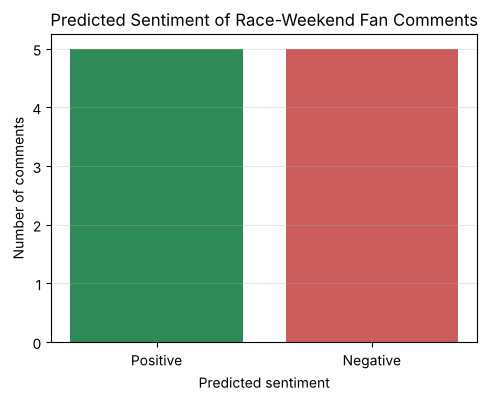

In [31]:
# Simple fan-sentiment summary, the kind of output a team's media desk would want
counts = race_df["Predicted"].value_counts()
plt.figure(figsize=(5.5, 4))
plt.bar(counts.index, counts.values, color=["seagreen" if i == "Positive" else "indianred" for i in counts.index])
plt.title("Predicted Sentiment of Race-Weekend Fan Comments")
plt.xlabel("Predicted sentiment"); plt.ylabel("Number of comments"); plt.grid(alpha=0.3, axis="y")
plt.show()

**What this shows.** The pipeline works as a first filter for fan feedback: strong, plain sentiment words carry over from F1 tweets to endurance-race comments. It will be weaker on comments where the sentiment is carried by motorsport terms rather than general words (for example "undercut worked" or "lost the stint to traffic"). Fixing that needs training data from WEC fans (ideally labelled by people rather than a lexicon), not a bigger RNN.

## 13. Discussion Questions

**1. What is an RNN and why is it suitable for text classification?**  
A Recurrent Neural Network reads a sequence one element at a time and keeps a hidden state that is updated at every step, so each step can use what came before. Text is a sequence where word order matters ("not good" is different from "good"), so an RNN fits better than a plain feed-forward network that treats the input as an unordered block.

**2. What is the purpose of the Embedding layer?**  
It converts each word id into a dense learned vector (128 numbers here). Raw integer ids carry no meaning (id 50 is not "close" to id 51), whereas embeddings are trained so that words used in similar contexts get similar vectors. It is also far smaller than one-hot encoding of 10,000 words.

**3. Why is padding required?**  
Tweets have different lengths, but a batch must be a rectangular array. Padding short tweets with zeros and truncating long ones gives every tweet the same length (50), so batches can be fed to the model.

**4. Why is sigmoid used in the output layer?**  
Sigmoid squashes the output into the range 0 to 1, which can be read as the probability of the positive class. With a threshold of 0.5 it gives the class label, and it pairs with binary cross-entropy.

**5. Why is binary cross-entropy used as the loss function?**  
For a two-class problem with a probability output, binary cross-entropy is −[y·log(p) + (1−y)·log(1−p)]. It punishes confident wrong predictions very heavily and gives smooth gradients with sigmoid, unlike accuracy which cannot be differentiated.

**6. What is the vanishing-gradient problem?**  
During backpropagation through time the gradient is multiplied by the recurrent weights and activation derivatives once for every time step. Over many steps these products shrink towards zero, so early words in the tweet barely influence the weight updates and the network cannot learn long-range dependencies. (The opposite case, exploding gradients, is handled with gradient clipping.)

**7. What happens when the number of RNN units is increased?**  
The hidden state gets larger, so the model has more capacity and more parameters, and each epoch takes longer. It can fit the training data better but may overfit, and for a SimpleRNN the benefit is limited by vanishing gradients (see Experiment A).

**8. What is overfitting?**  
When a model learns the training data too closely, including noise, so training accuracy is high but validation/test accuracy is clearly lower. It shows up as a growing gap between the training and validation curves.

**9. How can overfitting be reduced in an RNN?**  
Dropout (and `recurrent_dropout`) on the recurrent layer, early stopping on validation loss, fewer units, L2 regularisation, a smaller embedding, more training data, and using the validation split to choose the number of epochs.

**10. What is the difference between SimpleRNN, LSTM and GRU?**  
SimpleRNN has one tanh update and suffers from vanishing gradients. LSTM adds a separate cell state and three gates (input, forget, output) that control what is stored, forgotten and shown, so it can keep information over long spans. GRU is a lighter version with two gates (update, reset) and no separate cell state; it trains faster and often performs similarly to LSTM.

## 14. Final Model Selection

In [32]:
best_id = res_df["Test Accuracy"].idxmax()
print(f"Best single experiment by test accuracy: {best_id} ({res_df.loc[best_id,'Parameter']}) -> {res_df.loc[best_id,'Test Accuracy']:.4f}")
print(f"Two-layer RNN test accuracy: {acc2:.4f}")
print()
# Pick by validation accuracy (not test) to avoid choosing on the test set
val_best = res_df["Validation Accuracy"].idxmax()
print(f"Best by VALIDATION accuracy (the fair way to choose): {val_best} ({res_df.loc[val_best,'Parameter']}) -> val {res_df.loc[val_best,'Validation Accuracy']:.4f}, test {res_df.loc[val_best,'Test Accuracy']:.4f}")

Best single experiment by test accuracy: C3 (Batch = 128) -> 0.8389
Two-layer RNN test accuracy: 0.8245

Best by VALIDATION accuracy (the fair way to choose): C3 (Batch = 128) -> val 0.8270, test 0.8389


The final model is chosen on **validation** accuracy, and the test set is used only to report the result. If two settings are within a couple of points of each other, the cheaper one (fewer units, shorter training time) is preferred because the difference is inside the run-to-run noise.

## 15. Conclusion (≈150–200 words)

In [33]:
final = res_df.loc[val_best]
text = (
 f"In this lab I built a SimpleRNN sentiment classifier on about {len(data):,} labelled Formula 1 fan tweets using an Embedding layer, a recurrent layer and a sigmoid output, "
 f"and learned how padding, embeddings and the hidden state work together. The base model (64 units, 5 epochs, batch 64) reached "
 f"{test_acc*100:.1f}% test accuracy. Across the nine experiments the best validation result came from {val_best} "
 f"({final['Parameter']}), with {final['Test Accuracy']*100:.1f}% test accuracy. Going from 32 to 128 units changed test accuracy by "
 f"{a_gain*100:+.1f} points and going from 3 to 10 epochs changed it by {b_gain*100:+.1f} points, so more units {'helped' if a_gain>0.01 else 'did not clearly help'} and more epochs "
 f"{'helped' if b_gain>0.01 else 'did not clearly help'} test accuracy. The two-layer model reached "
 f"{acc2*100:.1f}% and trained for {time2:.0f}s against {single['Train Time (s)']:.0f}s for the single layer. "
 f"The limitations are the noisy SimpleRNN curves caused by vanishing gradients, the fact that the labels come from the VADER lexicon rather than from people, "
 f"and the weaker transfer to endurance-race comments, where racing slang is unknown to the model. An LSTM or GRU would keep information "
 f"over long sequences better and should give a more stable and higher accuracy, and human-labelled race comments would help the motorsport use."
)
print(text)
print("\nWord count:", len(text.split()))

In this lab I built a SimpleRNN sentiment classifier on about 27,092 labelled Formula 1 fan tweets using an Embedding layer, a recurrent layer and a sigmoid output, and learned how padding, embeddings and the hidden state work together. The base model (64 units, 5 epochs, batch 64) reached 73.6% test accuracy. Across the nine experiments the best validation result came from C3 (Batch = 128), with 83.9% test accuracy. Going from 32 to 128 units changed test accuracy by -1.2 points and going from 3 to 10 epochs changed it by -2.4 points, so more units did not clearly help and more epochs did not clearly help test accuracy. The two-layer model reached 82.5% and trained for 51s against 40s for the single layer. The limitations are the noisy SimpleRNN curves caused by vanishing gradients, the fact that the labels come from the VADER lexicon rather than from people, and the weaker transfer to endurance-race comments, where racing slang is unknown to the model. An LSTM or GRU would keep infor

*The paragraph above is generated from this run's measured numbers, so it matches the tables. If your report needs it in a text box, copy the printed paragraph.*